<a href="https://colab.research.google.com/github/mahak315/sdav_lab/blob/main/statslab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
np.random.seed(42)

In [3]:
x=np.linspace(-4,4,400)

In [4]:
std_normal=stats.norm(0,1)

In [7]:
print("68-95-99.7 rule:")
print(f"P(-1<Z<1)={std_normal.cdf(1)-std_normal.cdf(-1):.6f}")
print(f"P(-2<Z<2)={std_normal.cdf(2)-std_normal.cdf(-2):.6f}")
print(f"P(-3<Z<3)={std_normal.cdf(3)-std_normal.cdf(-3):.6f}")


68-95-99.7 rule:
P(-1<Z<1)=0.682689
P(-2<Z<2)=0.954500
P(-3<Z<3)=0.997300


In [8]:
#z-score standardization
mu_exam,sigma_exam=70,10
for score in[60,70,80,90]:
  z=(score-mu_exam)/sigma_exam
  pct=std_normal.cdf(z)*100
  print(f"Score={score}: Z={z:.2f}, Percentile={pct:.1f}%")

Score=60: Z=-1.00, Percentile=15.9%
Score=70: Z=0.00, Percentile=50.0%
Score=80: Z=1.00, Percentile=84.1%
Score=90: Z=2.00, Percentile=97.7%


In [10]:
#---exponential distribution----
lam=1.0
exp_dist=stats.expon(scale=1/lam)
print(f"exp(lam=1): Mean={exp_dist.mean()}, Var={exp_dist.var()}")
#Memoryless property
print(f"P(x>2) ={1-exp_dist.cdf(2):.6f}")
print(f"P(x>3|x>1) ={(1-exp_dist.cdf(3))/(1-exp_dist.cdf(1)):.6f}")

exp(lam=1): Mean=1.0, Var=1.0
P(x>2) =0.135335
P(x>3|x>1) =0.135335


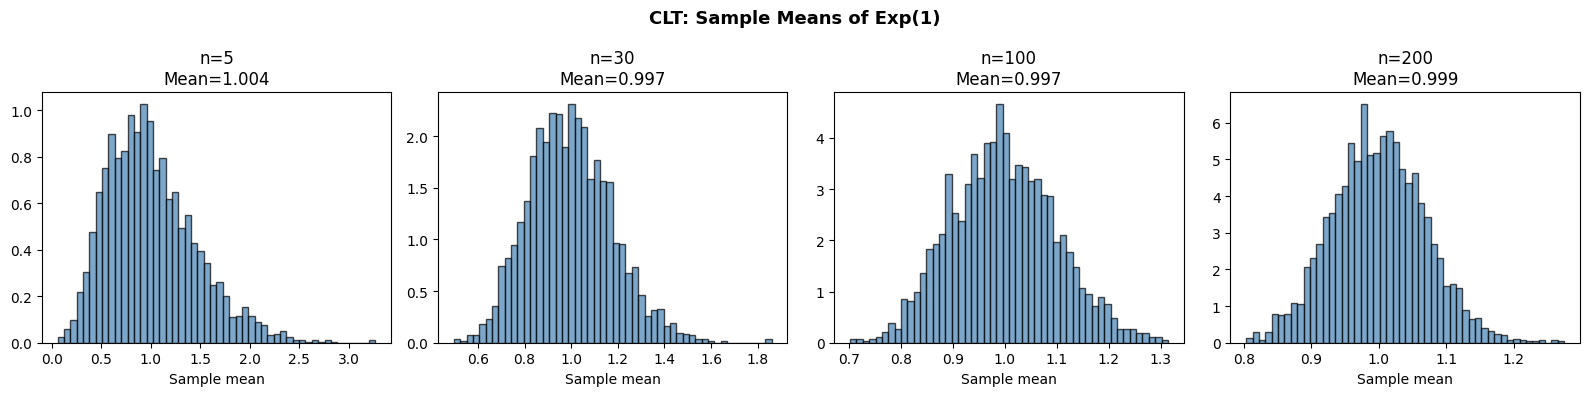

In [14]:
#----central limit theorem----
sample_sizes=[5,30,100,200]
fig,axes=plt.subplots(1,4,figsize=(16,4))
for i,n in enumerate(sample_sizes):
  means=[np.mean(np.random.exponential(1,n)) for _ in range(3000)]
  axes[i].hist(means,bins=50,density= True, color='steelblue',edgecolor="black", alpha=0.7)
  axes[i].set_title(f"n={n}\nMean={np.mean(means):.3f}")
  axes[i].set_xlabel("Sample mean")
fig.suptitle("CLT: Sample Means of Exp(1)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()